# CO abundance: surface deposition velocity experiments

Starting from each converged, saved state (all steady runs; the hot GJ 876 points use the haze-chemistry versions), the full coupled climate-photochemistry loop is rerun (CO2 re-solved for a 288 K surface) with a changed CO surface boundary condition:

| Experiment | CO deposition velocity | CO surface flux |
|---|---|---|
| baseline (saved runs) | 1e-8 cm/s | 1e9 molecules/cm2/s |
| `vdep0` | 0 | 0 |
| `vdep1.2e-4` | 1.2e-4 cm/s (abiotic maximum) | 0 |

Only the CO boundary condition changes; every other boundary condition is as saved. Results are in `sweep_results_co_vdep0/`, `sweep_results_co_vdep1.2e-4/`, and each run has a restartable folder in `saved_inputs/` (names end `_COvdep0_COflux0` / `_COvdep1.2e-4_COflux0`).

In [1]:
import json, glob
import numpy as np, matplotlib.pyplot as plt
def load(d): return [json.load(open(p)) for p in glob.glob(f'{d}/*.json')]
exps = {'vdep0': load('sweep_results_co_vdep0'), 'vdep1.2e-4': load('sweep_results_co_vdep1.2e-4')}
base = {}
for m in exps['vdep0']: base[(m['star'], m['S_Wm2'])] = json.load(open(f"saved_inputs/{m['co_experiment']['start_from']}/{m['co_experiment']['start_from']}_run.json"))
def table(star):
    rows = []
    for S in sorted({k[1] for k in base if k[0]==star}, reverse=True):
        r = {'S': S, 'base': base[(star,S)]}
        for e, ms in exps.items():
            for m in ms:
                if m['star']==star and m['S_Wm2']==S: r[e]=m
        rows.append(r)
    return rows
for star in ['Sun','GJ876']:
    print(star); print(f"{'S':>8} | {'baseline CO':>11} {'pCO2':>9} | {'vdep=0 CO':>10} {'pCO2':>9} {'T':>6} | {'vdep=1.2e-4 CO':>14} {'pCO2':>9} {'T':>6}")
    for r in table(star):
        b=r['base']; a=r.get('vdep0'); c=r.get('vdep1.2e-4')
        f=lambda m,k: f"{m['vmr']['CO']:{k}}" if m else '   n/a'
        print(f"{r['S']:8.2f} | {b['vmr']['CO']:11.2e} {b['pCO2_bar']:9.2e} | {f(a,'10.2e')} {a['pCO2_bar'] if a else float('nan'):9.2e} {a['T_surf_K'] if a else float('nan'):6.1f} | {f(c,'14.2e')} {c['pCO2_bar'] if c else float('nan'):9.2e} {c['T_surf_K'] if c else float('nan'):6.1f}")

Sun
       S | baseline CO      pCO2 |  vdep=0 CO      pCO2      T | vdep=1.2e-4 CO      pCO2      T
 1400.00 |    1.66e-06  4.65e-05 |   1.60e-06  4.57e-05  287.8 |       1.48e-06  4.57e-05  287.8
 1331.25 |    6.26e-06  2.64e-04 |   6.04e-06  2.58e-04  287.8 |       4.85e-06  2.58e-04  287.8
 1262.50 |    1.58e-05  1.09e-03 |   1.61e-05  1.14e-03  287.9 |       1.02e-05  1.14e-03  287.8
 1193.75 |    3.64e-05  3.97e-03 |   3.66e-05  4.02e-03  287.8 |       1.70e-05  4.24e-03  287.8
 1125.00 |    8.26e-05  1.29e-02 |   8.07e-05  1.28e-02  288.2 |       2.41e-05  1.39e-02  288.3
 1056.25 |    1.76e-04  3.25e-02 |   1.71e-04  3.21e-02  288.1 |       2.94e-05  3.56e-02  288.2
  987.50 |    4.23e-04  7.32e-02 |   4.07e-04  7.25e-02  288.1 |       3.24e-05  8.22e-02  288.2
  918.75 |    3.14e-03  1.54e-01 |   3.01e-03  1.53e-01  288.0 |       3.25e-05  1.78e-01  288.1
  850.00 |    1.52e-02  3.06e-01 |   1.82e-02  3.17e-01  288.1 |       2.92e-05  3.72e-01  288.1
  781.25 |    1.93e-02  6.

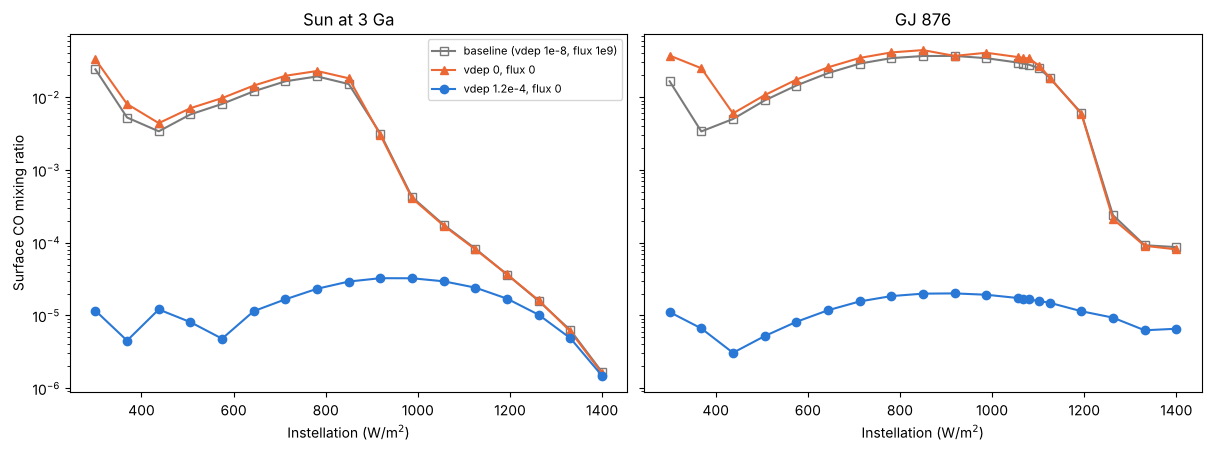

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True, sharey=True)
col = {'base':'#7a7a7a','vdep0':'#eb6834','vdep1.2e-4':'#2a78d6'}
lab = {'base':'baseline (vdep 1e-8, flux 1e9)','vdep0':'vdep 0, flux 0','vdep1.2e-4':'vdep 1.2e-4, flux 0'}
mk = {'base':'s','vdep0':'^','vdep1.2e-4':'o'}
for ax, star, title in [(axs[0],'Sun','Sun at 3 Ga'),(axs[1],'GJ876','GJ 876')]:
    rows = table(star)
    for k in ['base','vdep0','vdep1.2e-4']:
        xs=[r['S'] for r in rows if k in r]; ys=[r[k]['vmr']['CO'] for r in rows if k in r]
        ax.plot(xs, ys, mk[k]+'-', color=col[k], mfc='none' if k=='base' else col[k], label=lab[k])
    ax.set_yscale('log'); ax.set_xlabel('Instellation (W/m$^2$)'); ax.set_title(title)
axs[0].set_ylabel('Surface CO mixing ratio'); axs[0].legend(fontsize=8)
plt.show()

In [3]:
# other surface gases and the CO2 needed for 288 K, per experiment
for star in ['Sun','GJ876']:
    print(star)
    for r in table(star):
        for k in ['base','vdep0','vdep1.2e-4']:
            if k not in r: continue
            m=r[k]; v=m['vmr']
            print(f"  S={r['S']:8.2f} {k:11s} T={m['T_surf_K']:6.1f} pCO2={m['pCO2_bar']:.2e} CO2={v['CO2']:.2e} CO={v['CO']:.2e} O2={v['O2']:.1e} H2O={v['H2O']:.2e} CH4={v['CH4']:.2e} H2={v['H2']:.2e} steady={m['photochem_steady']}")

Sun
  S= 1400.00 base        T= 287.9 pCO2=4.65e-05 CO2=4.59e-05 CO=1.66e-06 O2=9.7e-15 H2O=8.06e-03 CH4=1.69e-06 H2=5.75e-03 steady=True
  S= 1400.00 vdep0       T= 287.8 pCO2=4.57e-05 CO2=4.51e-05 CO=1.60e-06 O2=9.8e-15 H2O=8.06e-03 CH4=1.68e-06 H2=5.73e-03 steady=True
  S= 1400.00 vdep1.2e-4  T= 287.8 pCO2=4.57e-05 CO2=4.51e-05 CO=1.48e-06 O2=1.0e-14 H2O=8.05e-03 CH4=1.68e-06 H2=5.55e-03 steady=True
  S= 1331.25 base        T= 287.9 pCO2=2.64e-04 CO2=2.60e-04 CO=6.26e-06 O2=6.3e-15 H2O=8.06e-03 CH4=4.45e-06 H2=5.62e-03 steady=True
  S= 1331.25 vdep0       T= 287.8 pCO2=2.58e-04 CO2=2.54e-04 CO=6.04e-06 O2=6.3e-15 H2O=8.06e-03 CH4=4.39e-06 H2=5.58e-03 steady=True
  S= 1331.25 vdep1.2e-4  T= 287.8 pCO2=2.58e-04 CO2=2.54e-04 CO=4.85e-06 O2=6.7e-15 H2O=8.05e-03 CH4=4.37e-06 H2=5.05e-03 steady=True
  S= 1262.50 base        T= 287.7 pCO2=1.09e-03 CO2=1.08e-03 CO=1.58e-05 O2=5.0e-15 H2O=8.08e-03 CH4=1.14e-05 H2=5.44e-03 steady=True
  S= 1262.50 vdep0       T= 287.9 pCO2=1.14e-03 CO2=1.12e-